In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    GITHUB_USER = "SinghSahiljit44"  # Es. sahiljit
    REPO_NAME = "Weather_forecasting"
    REPO_URL = f"https://github.com/{GITHUB_USER}/{REPO_NAME}.git"

    # Clona la repository se non è già stata clonata nella sessione
    if not os.path.exists(REPO_NAME):
        !git clone {REPO_URL}

    # Cambia la directory di lavoro nella root del progetto
    os.chdir(REPO_NAME)
    
    # Installa le dipendenze necessarie nell'ambiente di Colab
    %pip install -q -r requirements.txt
    
    PROJECT_ROOT = Path.cwd()
else:
    # --- CONFIGURAZIONE LOCALE  ---
    PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
    os.chdir(PROJECT_ROOT)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

print(f" [OK] Ambiente rilevato: {'Google Colab' if IN_COLAB else 'Locale'}")
print(f" [OK] Directory di lavoro impostata a: {Path.cwd()}")

 [OK] Ambiente rilevato: Locale
 [OK] Directory di lavoro impostata a: /home/matteo/Documents/GitHub/Weather_forecasting


# First off, Data preprocessing
In this next cell, we will preprocess data so that it will be available in the next steps for each model.

In [ ]:
import numpy as np
import pandas as pd
import src.utils.metrics as metrics
import matplotlib.pyplot as plt

from src.data.preprocessing import get_split
from src.utils.split import Split

split = get_split()
features = split.get_features()
split.define_target("t2m_mean")
(X_train, y_train), (X_val, y_val), (X_test, y_test) = split.get(features)


## Linear Regression - Temperature
Here below we can find the code for the linear regression algorithm.

In [ ]:
from sklearn.linear_model import LinearRegression
from src.utils.metrics import plot_rmse

models = LinearRegression().fit(X_train, y_train)

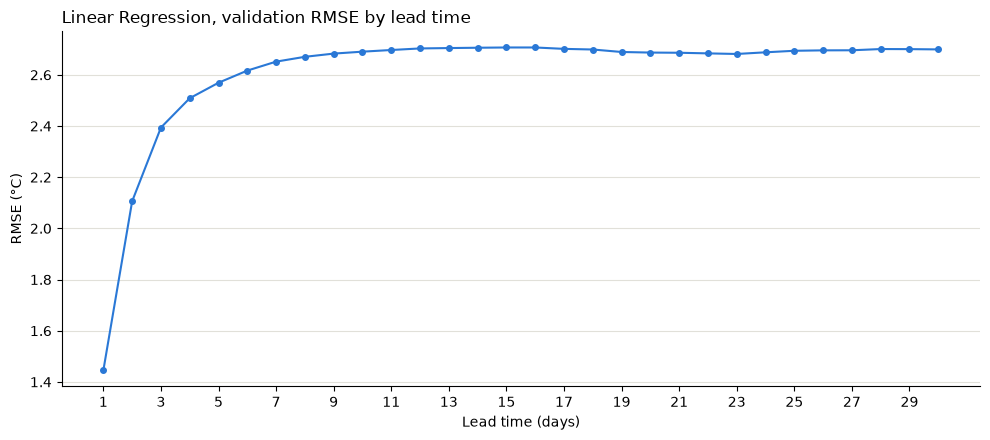

In [4]:
y_val_pred = models.predict(X_val)

plot_rmse(y_val, y_val_pred, "Linear Regression, validation RMSE by lead time", "°C")

In [5]:
y_test_pred = models.predict(X_test)
y_test_pred = pd.DataFrame(y_test_pred, index=y_test.index, columns=y_test.columns)

last = y_test.index[-1]
err = (y_test_pred.loc[last] - y_test.loc[last]).abs()
results = pd.DataFrame({
    "Actual temperature (°C)": y_test.loc[last],
    "Predicted temperature (°C)": y_test_pred.loc[last],
    "Within ±2 °C": err <= 2,
})
results.index.name = f"Lead time (days from {last.date()})"
display(results)

y_train_pred = models.predict(X_train)

table = metrics.metrics_table(
    {"Train": (y_train, y_train_pred), "Val": (y_val, y_val_pred), "Test": (y_test, y_test_pred)},
    tolerance=2,
)
display(table.style.format("{:.3f}"))

,Actual temperature (°C),Predicted temperature (°C),Within ±2 °C
Lead time (days from 2025-11-30),,,
1,8.484374,8.965384,True
2,10.704518,10.010750,True
3,9.430755,10.327299,True
4,9.938348,10.391022,True
5,10.489013,10.401770,True
6,10.799903,10.374801,True
7,9.645624,10.224061,True
8,10.133666,10.041736,True
9,8.983125,9.883221,True


Text(0, 0.5, 'RMSE (°C)')

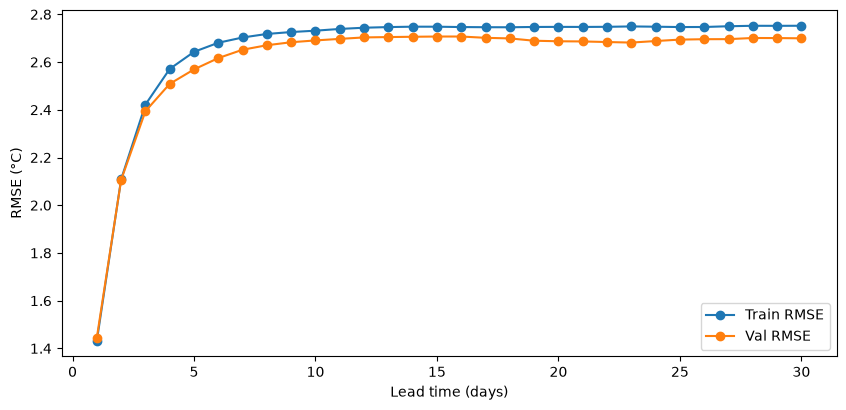

In [6]:
# check for overfitting

tr = pd.DataFrame(models.predict(X_train), index=y_train.index, columns=y_train.columns)
va = pd.DataFrame(models.predict(X_val),   index=y_val.index,   columns=y_val.columns)

gap = pd.DataFrame({
    "Train RMSE": {h: metrics.get_rmse(y_train[h], tr[h]) for h in y_train.columns},
    "Val RMSE":   {h: metrics.get_rmse(y_val[h],   va[h]) for h in y_val.columns},
})
gap["Gap"] = gap["Val RMSE"] - gap["Train RMSE"]
gap["Val bias"] = (y_val - va).mean()   # mean error on validation; > 0 means the model forecasts too cold
# display(gap)

ax = gap[["Train RMSE", "Val RMSE"]].plot(marker="o", figsize=(10, 4.5))
ax.set_xlabel("Lead time (days)")
ax.set_ylabel("RMSE (°C)")

## Linear Regression - Precipitations

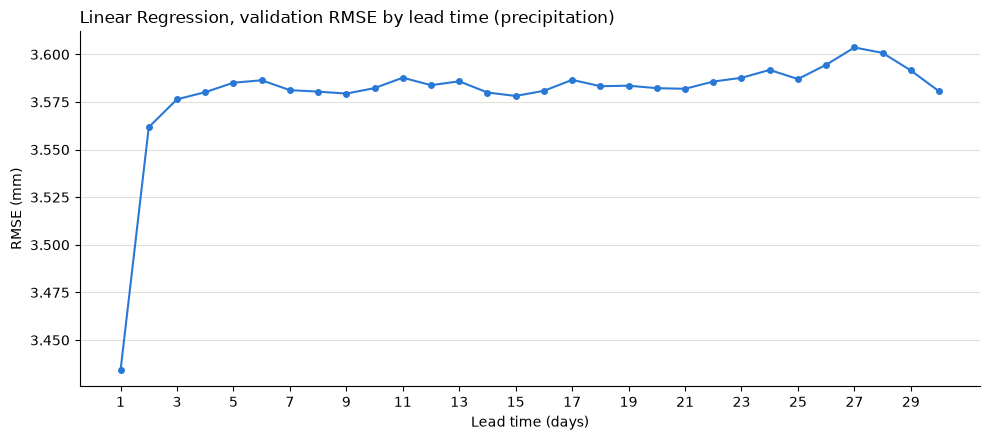

,Actual precipitation (mm),Predicted precipitation (mm)
Lead time (days from 2025-11-30),,
1,0.037551,1.157445
2,3.276247,1.822326
3,0.010955,2.107750
4,21.338820,2.098949
5,1.580447,2.002372
6,0.145108,1.861009
7,0.006559,2.015856
8,0.005811,2.006885
9,0.000000,2.224868


In [7]:
#   Training: own Split and own variable names, so the temperature ones are not overwritten
split_p = get_split()
split_p.define_target("tp_mm")
(Xp_train, yp_train), (Xp_val, yp_val), (Xp_test, yp_test) = split_p.get(features)

lr_p = LinearRegression().fit(Xp_train, yp_train)

#   Validation
yp_val_pred = np.clip(lr_p.predict(Xp_val), 0, None)
plot_rmse(yp_val, yp_val_pred, "Linear Regression, validation RMSE by lead time (precipitation)", "mm")

#   Test
yp_test_pred = np.clip(lr_p.predict(Xp_test), 0, None)
yp_test_pred = pd.DataFrame(yp_test_pred, index=yp_test.index, columns=yp_test.columns)

last = yp_test.index[-1]
results = pd.DataFrame({
    "Actual precipitation (mm)": yp_test.loc[last],
    "Predicted precipitation (mm)": yp_test_pred.loc[last],
})
results.index.name = f"Lead time (days from {last.date()})"
display(results)

yp_train_pred = np.clip(lr_p.predict(Xp_train), 0, None)

table_p = metrics.metrics_table(
    {"Train": (yp_train, yp_train_pred), "Val": (yp_val, yp_val_pred), "Test": (yp_test, yp_test_pred)},
)
display(table_p.style.format("{:.3f}"))

## Conclusions about Linear Regression
While for the temperature it works quite well, Linear Regressions fully shows its weakness when it comes to predict the following days' precipitations: this was expected, since rains usually don't behave in a "linear" way.



We will keep the results for the temperature.

One (and maybe the only one) hyperparameter is the days' lag: we;